# Phase 2 - Data Exploration

**Thesis:** Predictive Maintenance and Anomaly Detection for Industrial IoT Telemetry Using Machine Learning

**Objective.** Describe the FD001 and FD002 data before changing anything: check data quality, identify the operating conditions, find which sensors carry information, and look at how sensor readings change as engines wear out.

**Why this is needed.** Every preprocessing decision in Phase 3 (which sensors to drop, how to normalise) has to be justified by evidence from the data. This notebook produces that evidence.

**Leakage rule.** Sensor statistics below use the *training* engines only. The test files are inspected only for structure (size, missing values, trajectory length).

All calculations live in `src/exploration.py`; this notebook calls them and shows the results.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl
from src import exploration as ex
from src import plot_style as ps

pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 4)

# Write every Phase 2 table and figure to results/ in one step
saved = ex.run_all()
for name, path in saved.items():
    print(f'{name:40s} -> {path.relative_to(dl.PROJECT_ROOT)}')

phase2_data_quality                      -> results\tables\phase2_data_quality.csv
phase2_operating_conditions              -> results\tables\phase2_operating_conditions.csv
phase2_sensor_summary_FD001              -> results\tables\phase2_sensor_summary_FD001.csv
phase2_sensor_summary_FD002              -> results\tables\phase2_sensor_summary_FD002.csv
fig01_dataset_distribution               -> results\figures\fig01_dataset_distribution.png
fig02a_sensor_trends_FD001               -> results\figures\fig02a_sensor_trends_FD001.png
fig02b_operating_condition_effect        -> results\figures\fig02b_operating_condition_effect.png


## 1. Data quality

Missing values, non-finite values and duplicate records in all four trajectory files.

In [2]:
ex.quality_report()

,subset,split,rows,missing_values,non_finite_values,duplicate_rows,duplicate_unit_cycle,repeated_measurement_rows
0,FD001,train,20631,0,0,0,0,0
1,FD001,test,13096,0,0,0,0,0
2,FD002,train,53759,0,0,0,0,0
3,FD002,test,33991,0,0,0,0,0


**Reading the table.** All four files are complete: no missing or non-finite values, no duplicated rows, and no engine has two rows for the same cycle. No two rows share identical settings and sensor readings either. Nothing needs to be imputed or removed for data-quality reasons.

## 2. Operating conditions

The three settings are altitude (thousand feet), Mach number and throttle resolver angle. They take a few nominal values with small noise, so rounding them groups rows by flight regime.

In [3]:
pd.concat([ex.operating_conditions(s) for s in dl.SUBSETS], ignore_index=True)

,subset,altitude_kft / mach / throttle,rows,share_percent
0,FD001,0 / 0.00 / 100,20631,100.0
1,FD002,0 / 0.00 / 100,8044,15.0
2,FD002,10 / 0.25 / 100,8096,15.1
3,FD002,20 / 0.70 / 100,8122,15.1
4,FD002,25 / 0.62 / 60,8002,14.9
5,FD002,35 / 0.84 / 100,8037,15.0
6,FD002,42 / 0.84 / 100,13458,25.0


**Reading the table.** FD001 is flown at one condition (sea level). FD002 has six conditions, matching the dataset readme. Five of them each hold about 15% of the rows and one holds 25%.

## 3. Sensor statistics (training engines)

- `constant`: the column has a single value in the whole file.
- `constant_within_condition`: the column never changes inside any one operating condition.
- `spearman_vs_remaining`: rank correlation between the sensor and the number of cycles left before failure. Values far from 0 mean the sensor drifts steadily as the engine degrades.
- `variance_from_condition`: share of the sensor's variance explained by the operating condition alone.
- `spearman_within_condition`: the same correlation after subtracting each condition's mean.

In [4]:
cols = ['column', 'symbol', 'mean', 'std', 'min', 'max', 'n_unique', 'constant',
        'constant_within_condition', 'spearman_vs_remaining',
        'variance_from_condition', 'spearman_within_condition']
fd001 = ex.sensor_summary('FD001')
fd001[cols]

,column,symbol,mean,std,min,max,n_unique,constant,constant_within_condition,spearman_vs_remaining,variance_from_condition,spearman_within_condition
0,setting_1,,-8.8701e-06,0.0022,-0.0087,0.0087,158,False,False,-0.0013,0.0,-0.0013
1,setting_2,,2.3508e-06,0.0003,-0.0006,0.0006,13,False,False,-0.0038,0.0,-0.0038
2,setting_3,,1.0000e+02,0.0000,100.0000,100.0000,1,True,True,NaN,NaN,NaN
3,s1,T2,5.1867e+02,0.0000,518.6700,518.6700,1,True,True,NaN,NaN,NaN
4,s2,T24,6.4268e+02,0.5001,641.2100,644.5300,310,False,False,-0.6286,0.0,-0.6286
5,s3,T30,1.5905e+03,6.1311,1571.0400,1616.9100,3012,False,False,-0.6056,0.0,-0.6056
6,s4,T50,1.4089e+03,9.0006,1382.2500,1441.4900,4051,False,False,-0.7018,0.0,-0.7018
7,s5,P2,1.4620e+01,0.0000,14.6200,14.6200,1,True,True,NaN,NaN,NaN
8,s6,P15,2.1610e+01,0.0014,21.6000,21.6100,2,False,False,-0.1281,0.0,-0.1281
9,s7,P30,5.5337e+02,0.8851,549.8500,556.0600,513,False,False,0.6788,0.0,0.6788


In [5]:
fd002 = ex.sensor_summary('FD002')
fd002[cols]

,column,symbol,mean,std,min,max,n_unique,constant,constant_within_condition,spearman_vs_remaining,variance_from_condition,spearman_within_condition
0,setting_1,,23.9984,14.7474,0.0000,42.0080,536,False,False,0.0020,1.0000,0.0010
1,setting_2,,0.5721,0.3100,0.0000,0.8420,105,False,False,0.0019,1.0000,0.0024
2,setting_3,,94.0460,14.2377,60.0000,100.0000,2,False,True,0.0043,1.0000,NaN
3,s1,T2,472.9102,26.3897,445.0000,518.6700,6,False,True,-0.0020,1.0000,NaN
4,s2,T24,579.6724,37.2894,535.5300,644.5200,1590,False,False,-0.1022,0.9999,-0.5895
5,s3,T30,1419.9710,105.9463,1243.7300,1612.8800,12305,False,False,-0.1158,0.9971,-0.5747
6,s4,T50,1205.4420,119.1234,1023.7700,1439.2300,15411,False,False,-0.1652,0.9957,-0.6820
7,s5,P2,8.0320,3.6138,3.9100,14.6200,6,False,True,-0.0017,1.0000,NaN
8,s6,P15,11.6007,5.4318,5.7100,21.6100,14,False,False,-0.0464,1.0000,-0.3557
9,s7,P30,282.6068,146.0053,136.8000,555.8200,2067,False,False,0.0770,1.0000,0.4874


In [6]:
sensors = lambda t: t[t['column'].isin(dl.SENSOR_COLS)]
pd.DataFrame({
    'constant sensors': [', '.join(sensors(t).loc[sensors(t)['constant'], 'column']) or 'none' for t in (fd001, fd002)],
    'max |Spearman| raw': [sensors(t)['spearman_vs_remaining'].abs().max() for t in (fd001, fd002)],
    'max |Spearman| within condition': [sensors(t)['spearman_within_condition'].abs().max() for t in (fd001, fd002)],
    'median variance share from condition': [sensors(t)['variance_from_condition'].median() for t in (fd001, fd002)],
}, index=['FD001', 'FD002'])

,constant sensors,max |Spearman| raw,max |Spearman| within condition,median variance share from condition
FD001,"s1, s5, s10, s16, s18, s19",0.7181,0.7181,0.0000
FD002,none,0.2468,0.7135,0.9998


**Reading the tables.**

- *FD001.* Six sensors (s1, s5, s10, s16, s18, s19) and setting 3 never change, so they cannot help any model. Sensor s6 takes only two values (21.60 and 21.61) and is almost uncorrelated with remaining life. The other sensors drift with wear; the strongest are s11, s4, s12 and s7.
- *FD002.* No sensor is constant over the whole file, but s1, s5, s18 and s19 are constant inside every operating condition, so they only repeat which condition the engine is in. For almost every sensor, more than 99% of the variance comes from the operating condition. As a result the raw correlation with remaining life is weak for all sensors.
- After removing each condition's mean, the FD002 correlations rise to levels close to FD001. The degradation signal is present in FD002 but hidden behind the regime changes.

These correlations describe the training data only. They are not model results.

## 4. Figure 1 - Dataset distribution

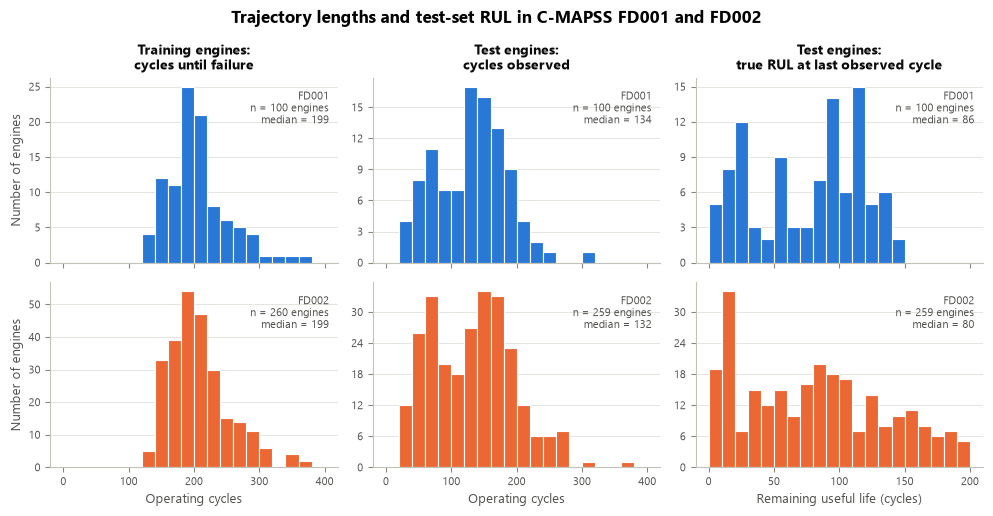

In [7]:
fig = ex.plot_dataset_distribution()
plt.show()

**Reading the figure.** Training engines run until failure and last between 128 and 378 cycles, with a median of 199 in both subsets. Test engines are cut off before failure, so their observed length is shorter and more spread out. The true RUL of the test engines covers the whole range from a few cycles to well above 125, which matters when the 125-cycle cap is applied in Phase 3.

## 5. Figure 2a - Sensor trends over operating cycles (FD001)

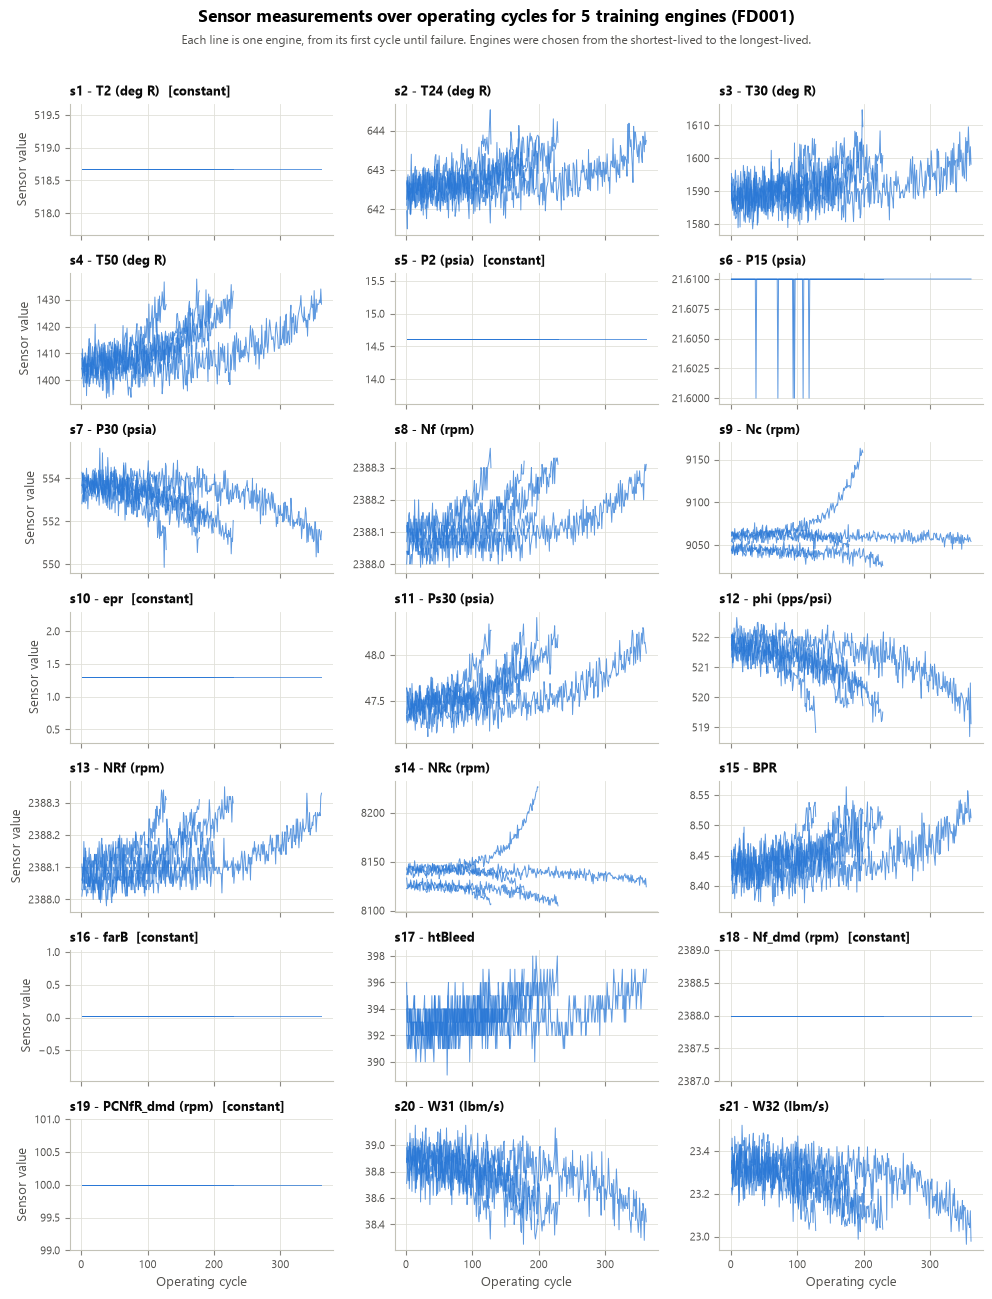

In [8]:
fig = ex.plot_sensor_trends('FD001')
plt.show()

**Reading the figure.** The six constant sensors appear as flat lines. The informative sensors stay roughly level in early life and then drift up or down as failure approaches. This flat-then-drifting shape is the reason a capped (piecewise linear) RUL target is commonly used: early in life the sensors do not yet show how much life remains. Sensors s9 and s14 behave differently from engine to engine.

## 6. Figure 2b - Effect of operating conditions (FD001 vs FD002)

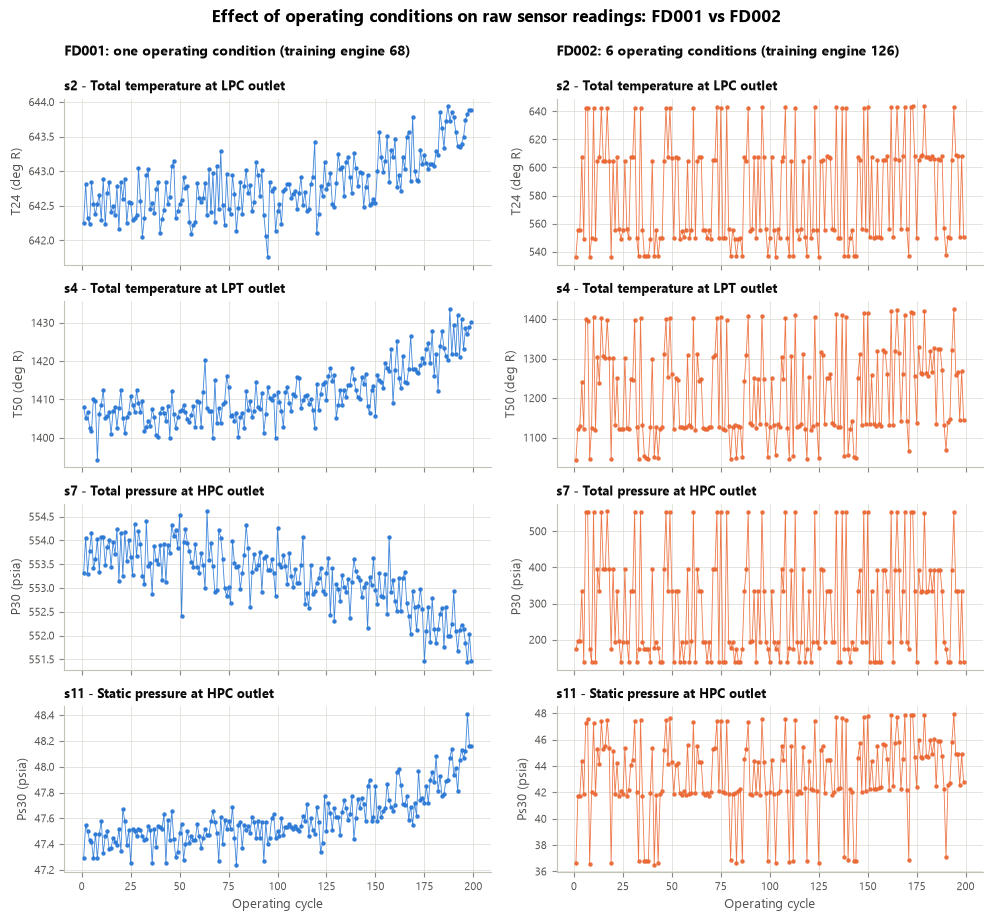

In [9]:
fig = ex.plot_condition_effect()
plt.show()

**Reading the figure.** In FD001 the wear trend is visible directly in the raw readings. In FD002 the same sensors jump between levels every cycle as the engine changes flight regime, and the jumps are far larger than the wear trend (compare the y-axis ranges). The trend can still be seen faintly inside each level.

## 7. Findings carried into Phase 3

1. No cleaning is needed for missing values or duplicates.
2. FD001: s1, s5, s10, s16, s18, s19 are constant and are candidates for removal. s6 is nearly constant.
3. FD002: no sensor is constant globally, so a simple "drop constant columns" rule removes nothing there.
4. FD002 sensor values are dominated by the operating condition. Normalising within each operating condition is a candidate preprocessing step, to be compared against dataset-wide normalisation.
5. Sensor behaviour is flat in early life, which supports the capped RUL target.